In [1]:
# Prédiction du décrochage scolaire et de la réussite académique
#Mini-projet Machine Learning, dataset UCI n°697 : *Predict Students' Dropout and Academic Success*.

#**Partie 1 : exploration des données, prétraitement, arbre de décision personnalisé et sélection des caractéristiques.**

In [2]:
# --- Bibliothèques ---
import numpy as np                 # calcul numérique (utilisé pour l'arbre personnalisé)
import pandas as pd                # manipulation de tableaux de données
import matplotlib.pyplot as plt    # graphiques
import seaborn as sns              # graphiques statistiques plus lisibles

# --- Paramètres communs à tout le groupe ---
SEED = 42            # graine aléatoire unique : garantit des résultats reproductibles
np.random.seed(SEED)

# Affichage : montrer toutes les colonnes d'un tableau
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [3]:
import os
os.makedirs("figures", exist_ok=True)   # crée le dossier "figures" s'il n'existe pas déjà

In [4]:
# Le fichier utilise le point-virgule comme séparateur (et non la virgule)
df = pd.read_csv("data.csv", sep=";")

# Certains noms de colonnes contiennent des espaces ou tabulations parasites
# (ex. "Daytime/evening attendance\t") : on les nettoie pour éviter des erreurs.
df.columns = df.columns.str.strip()

print("Dimensions (lignes, colonnes) :", df.shape)
df.head()

Dimensions (lignes, colonnes) : (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [5]:
# Types de chaque colonne et nombre de valeurs non nulles
df.info()

# Valeurs manquantes par colonne (on attend 0 partout, d'après la page UCI)
print("\nTotal de valeurs manquantes :", df.isna().sum().sum())

# Lignes dupliquées (identiques sur toutes les colonnes)
print("Nombre de doublons :", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

          effectif  pourcentage (%)
Target                             
Graduate      2209            49.93
Dropout       1421            32.12
Enrolled       794            17.95


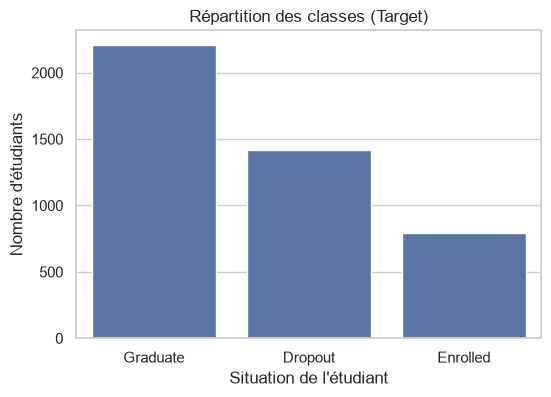

In [6]:
# Effectif et pourcentage de chaque classe
effectifs = df["Target"].value_counts()
pourcentages = df["Target"].value_counts(normalize=True).mul(100).round(2)
print(pd.DataFrame({"effectif": effectifs, "pourcentage (%)": pourcentages}))

# Graphique : permet de voir le déséquilibre des classes
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Target", order=effectifs.index)
plt.title("Répartition des classes (Target)")
plt.xlabel("Situation de l'étudiant")
plt.ylabel("Nombre d'étudiants")
plt.savefig("figures/01_repartition_classes.png", dpi=200, bbox_inches="tight")
plt.show()

In [7]:
# Cette table aide à distinguer les variables catégorielles (peu de valeurs distinctes, codées par des nombres) des variables vraiment numériques.
resume = pd.DataFrame({
    "type": df.dtypes,
    "valeurs_distinctes": df.nunique(),
    "min": df.select_dtypes("number").min(),
    "max": df.select_dtypes("number").max(),
})
resume.sort_values("valeurs_distinctes")

,type,valeurs_distinctes,min,max
Educational special needs,int64,2,0.00,1.000000
Displaced,int64,2,0.00,1.000000
Gender,int64,2,0.00,1.000000
International,int64,2,0.00,1.000000
Debtor,int64,2,0.00,1.000000
Daytime/evening attendance,int64,2,0.00,1.000000
Tuition fees up to date,int64,2,0.00,1.000000
Scholarship holder,int64,2,0.00,1.000000
Target,str,3,NaN,NaN
Marital status,int64,6,1.00,6.000000


In [8]:
df.describe().T   # moyenne, écart-type, min, quartiles, max pour chaque variable

,count,mean,std,min,25%,50%,75%,max
Marital status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


In [9]:
# --- Définition des groupes de variables ---
TARGET = "Target"

# Variables binaires : déjà codées 0/1, aucun encodage nécessaire
binary_cols = [
    "Educational special needs", "Displaced", "Gender", "International",
    "Debtor", "Daytime/evening attendance", "Tuition fees up to date",
    "Scholarship holder",
]

# Variables catégorielles nominales : les nombres sont des CODES sans ordre
# (ex. Course = 9500 n'est pas "plus grand" que Course = 33)
nominal_cols = [
    "Marital status", "Application mode", "Course", "Previous qualification",
    "Nacionality", "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation",
]

# Variables numériques : de vraies quantités (notes, nombres d'unités, âge, taux)
semester_cols = [c for c in df.columns if c.startswith("Curricular units")]
macro_cols = ["Unemployment rate", "Inflation rate", "GDP"]
numeric_cols = (
    ["Application order", "Previous qualification (grade)",
     "Admission grade", "Age at enrollment"]
    + semester_cols + macro_cols
)

# --- Vérifications de cohérence ---
all_features = binary_cols + nominal_cols + numeric_cols
assert len(all_features) == 36, "Il devrait y avoir 36 variables"
assert len(set(all_features)) == len(all_features), "Une variable est dans deux groupes"
assert set(all_features) == set(df.columns) - {TARGET}, "Variable oubliée ou en trop"
assert TARGET not in all_features, "Target ne doit jamais être dans X"

print(f"Binaires : {len(binary_cols)} | Nominales : {len(nominal_cols)} | "
      f"Numériques : {len(numeric_cols)} (dont {len(semester_cols)} de semestre)")

Binaires : 8 | Nominales : 9 | Numériques : 19 (dont 12 de semestre)


In [10]:
# Pour chaque variable binaire : % d'étudiants en abandon (Dropout) selon la valeur 0 ou 1
taux_abandon = pd.DataFrame({
    c: df.groupby(c)[TARGET].apply(lambda s: (s == "Dropout").mean() * 100).round(1)
    for c in binary_cols
}).T
taux_abandon.columns = ["% Dropout si valeur = 0", "% Dropout si valeur = 1"]
taux_abandon

,% Dropout si valeur = 0,% Dropout si valeur = 1
Educational special needs,32.1,33.3
Displaced,37.6,27.6
Gender,25.1,45.1
International,32.2,29.1
Debtor,28.3,62.0
Daytime/evening attendance,42.9,30.8
Tuition fees up to date,86.6,24.7
Scholarship holder,38.7,12.2


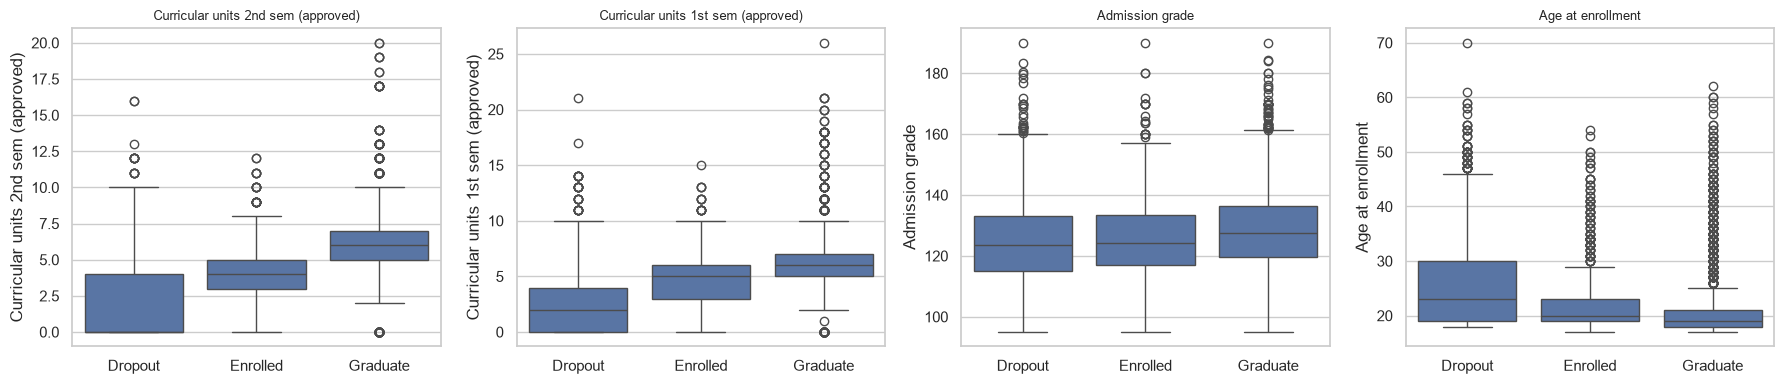

In [11]:
# Distribution de quelques variables importantes selon la classe réelle
cles = ["Curricular units 2nd sem (approved)", "Curricular units 1st sem (approved)",
        "Admission grade", "Age at enrollment"]
ordre = ["Dropout", "Enrolled", "Graduate"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, cles):
    sns.boxplot(data=df, x=TARGET, y=c, order=ordre, ax=ax)
    ax.set_title(c, fontsize=9)
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig("figures/02_boxplots_variables_cles.png", dpi=200, bbox_inches="tight")
plt.show()

Curricular units 2nd sem (grade)                  877
Curricular units 1st sem (grade)                  726
Curricular units 1st sem (credited)               577
Application order                                 541
Curricular units 2nd sem (credited)               530
Age at enrollment                                 441
Curricular units 1st sem (enrolled)               424
Curricular units 2nd sem (enrolled)               369
Curricular units 1st sem (without evaluations)    294
Curricular units 2nd sem (without evaluations)    282
dtype: int64


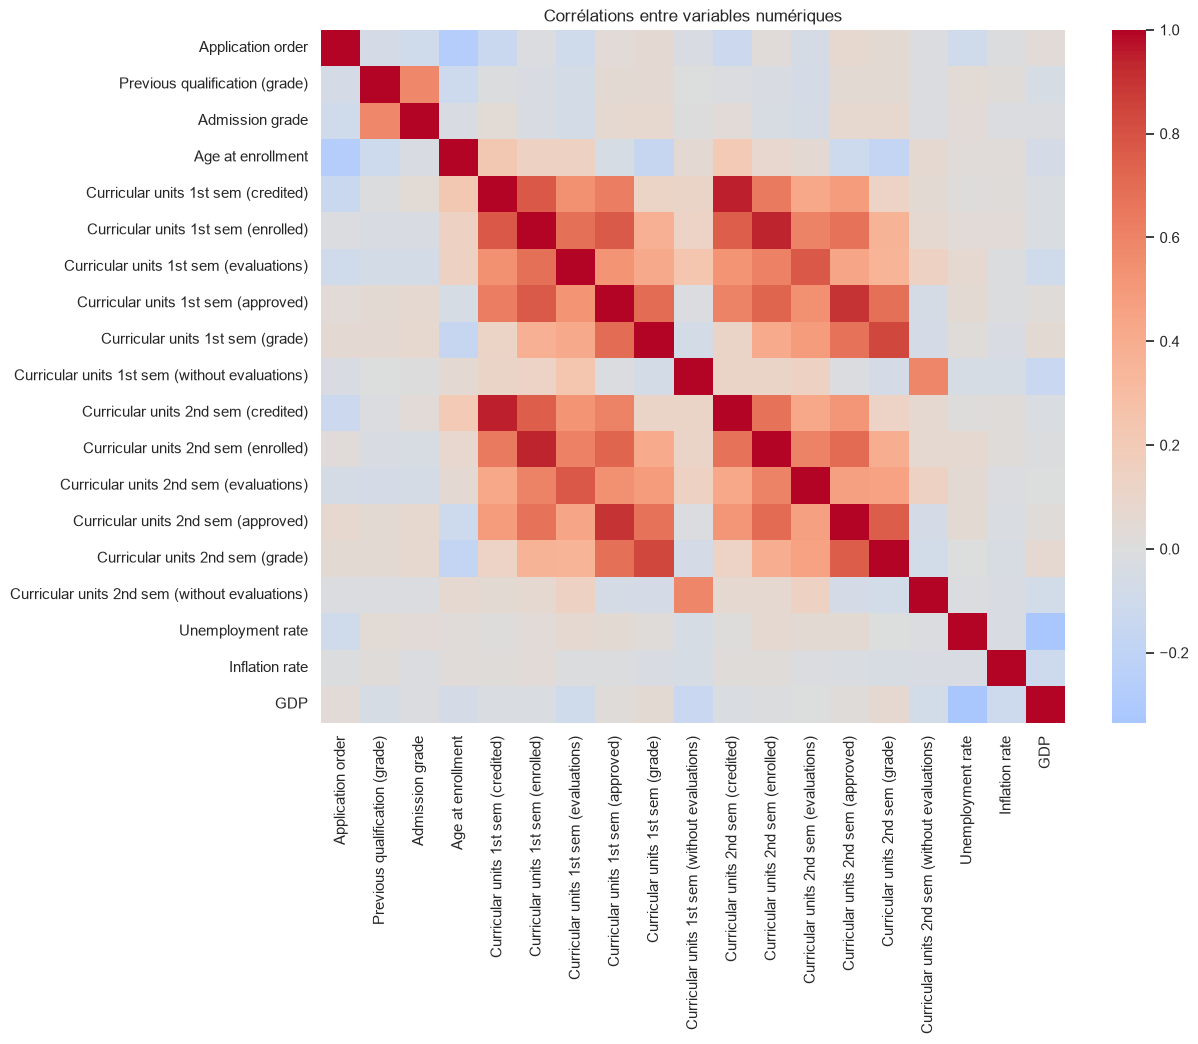

In [12]:
# --- Valeurs aberrantes (règle de l'écart interquartile, IQR) ---
# Un point est "atypique" s'il est au-delà de 1,5 × IQR des quartiles Q1 / Q3.
# On ne SUPPRIME rien ici : on regarde seulement si elles semblent plausibles.
Q1, Q3 = df[numeric_cols].quantile(0.25), df[numeric_cols].quantile(0.75)
IQR = Q3 - Q1
hors_bornes = ((df[numeric_cols] < Q1 - 1.5 * IQR) | (df[numeric_cols] > Q3 + 1.5 * IQR))
print(hors_bornes.sum().sort_values(ascending=False).head(10))

# --- Corrélations entre variables numériques ---
plt.figure(figsize=(12, 9))
sns.heatmap(df[numeric_cols].corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Corrélations entre variables numériques")
plt.savefig("figures/03_correlations.png", dpi=200, bbox_inches="tight")
plt.show()

In [13]:
# Les notes à 0 sont-elles des erreurs ? Elles devraient correspondre à des étudiants
# sans unité validée (donc plausibles), pas à des valeurs manquantes déguisées.
g0 = df["Curricular units 2nd sem (grade)"] == 0
print("Étudiants avec note du 2e semestre = 0 :", g0.sum())
print("Parmi eux, avec 0 unité validée au 2e semestre :",
      (df.loc[g0, "Curricular units 2nd sem (approved)"] == 0).sum())
print("Effectif de la valeur 1 pour 'Educational special needs' :",
      df["Educational special needs"].sum())

Étudiants avec note du 2e semestre = 0 : 870
Parmi eux, avec 0 unité validée au 2e semestre : 870
Effectif de la valeur 1 pour 'Educational special needs' : 51


In [14]:
from sklearn.model_selection import train_test_split

CLASSES = ["Dropout", "Enrolled", "Graduate"]   # ordre fixe des classes pour tout le groupe

X = df[all_features].copy()      # variables explicatives (SANS Target)
y = df[TARGET].copy()            # variable cible

# Découpage 80 % entraînement / 20 % test.
# stratify=y : chaque ensemble garde les mêmes proportions de classes.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
print("Train :", X_train.shape, "| Test :", X_test.shape)

# Vérification : proportions des classes dans chaque ensemble
props = pd.DataFrame({
    "complet": y.value_counts(normalize=True),
    "train": y_train.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).mul(100).round(2)
print(props)

# Garde-fous : aucun étudiant dans les deux ensembles, et pas de Target dans X
assert set(X_train.index).isdisjoint(set(X_test.index))
assert TARGET not in X_train.columns

Train : (3539, 36) | Test : (885, 36)
          complet  train   test
Target                         
Graduate    49.93  49.93  49.94
Dropout     32.12  32.13  32.09
Enrolled    17.95  17.94  17.97


In [15]:
import os, json
os.makedirs("data_split", exist_ok=True)

# Données BRUTES (non normalisées) : chacun applique ensuite le prétraitement
# avec les fonctions ci-dessous, en ne l'apprenant que sur le train.
X_train.reset_index(drop=True).to_csv("data_split/X_train.csv", index=False)
X_test.reset_index(drop=True).to_csv("data_split/X_test.csv", index=False)
y_train.reset_index(drop=True).to_csv("data_split/y_train.csv", index=False)
y_test.reset_index(drop=True).to_csv("data_split/y_test.csv", index=False)

# Fichier de configuration partagé : graine, classes, groupes de variables
config = {
    "seed": SEED, "test_size": 0.20, "classes": CLASSES,
    "binary_cols": binary_cols, "nominal_cols": nominal_cols,
    "numeric_cols": numeric_cols,
}
with open("data_split/config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)
print("Fichiers sauvegardés dans data_split/")

Fichiers sauvegardés dans data_split/


In [16]:

def fit_preprocessor(X_train, features, min_count=20):
    """Apprend les paramètres de prétraitement sur le TRAIN uniquement.
    - numériques : moyenne et écart-type (standardisation)
    - nominales  : catégories ayant au moins `min_count` étudiants dans le train ;
                   les autres seront regroupées dans une colonne "autre"
    - binaires   : inchangées
    min_count=1 désactive le regroupement."""
    p = {"features": list(features)}
    p["num"] = [c for c in features if c in numeric_cols]
    p["nom"] = [c for c in features if c in nominal_cols]
    p["bin"] = [c for c in features if c in binary_cols]
    p["mean"] = X_train[p["num"]].mean()
    p["std"] = X_train[p["num"]].std(ddof=0).replace(0, 1)
    p["cats"], p["a_autre"] = {}, {}
    for c in p["nom"]:
        comptes = X_train[c].value_counts()
        p["cats"][c] = sorted(comptes[comptes >= min_count].index)   # catégories conservées
        p["a_autre"][c] = bool((comptes < min_count).any())          # y a-t-il des rares ?
    return p


def transform_preprocessor(X, p):
    """Applique les paramètres appris (identiques pour train et test)."""
    parts = [(X[p["num"]] - p["mean"]) / p["std"],        # numériques standardisées
             X[p["bin"]].astype(float)]                   # binaires inchangées
    for c in p["nom"]:
        cols = {f"{c}={cat}": (X[c] == cat).astype(float) for cat in p["cats"][c]}
        # Colonne "autre" : catégories rares du train ET catégories inconnues au test
        if p["a_autre"][c]:
            cols[f"{c}=autre"] = (~X[c].isin(p["cats"][c])).astype(float)
        parts.append(pd.DataFrame(cols, index=X.index))
    return pd.concat(parts, axis=1)


# Test sur les 36 variables, avec comparaison avant / après regroupement
prep = fit_preprocessor(X_train, all_features, min_count=20)
Xtr_p = transform_preprocessor(X_train, prep)
Xte_p = transform_preprocessor(X_test, prep)
print("Avec regroupement (min_count=20) :", Xtr_p.shape, Xte_p.shape)
print("Sans regroupement (min_count=1)  :",
      transform_preprocessor(X_train, fit_preprocessor(X_train, all_features, min_count=1)).shape)



Avec regroupement (min_count=20) : (3539, 119) (885, 119)
Sans regroupement (min_count=1)  : (3539, 236)


In [17]:
def entropie_depuis_effectifs(effectifs):
    """Entropie de Shannon (en bits) à partir d'effectifs par classe.
    H = - somme( p_k * log2(p_k) ), avec p_k = proportion de la classe k.
    - 0 si le groupe est pur (une seule classe) ; maximale si les classes sont équilibrées.
    effectifs : tableau (K,) pour un groupe, ou (m, K) pour m groupes à la fois."""
    eff = np.atleast_2d(np.asarray(effectifs, dtype=float))
    total = eff.sum(axis=1, keepdims=True)
    # proportions (0 si le groupe est vide, pour éviter une division par zéro)
    p = np.divide(eff, total, out=np.zeros_like(eff), where=total > 0)
    # on remplace p=0 par 1 dans le log : 0*log(0) est alors compté comme 0
    log_p = np.log2(np.where(p > 0, p, 1.0))
    h = 0.0 - (p * log_p).sum(axis=1)
    return h[0] if np.ndim(effectifs) == 1 else h

In [18]:
class Noeud:
    """Un nœud de l'arbre : soit une feuille (prédiction), soit une question."""
    def __init__(self):
        self.est_feuille = True   # devient False si on trouve une séparation
        self.feature = None       # variable utilisée pour séparer
        self.type = None          # "num" (x <= seuil) ou "nom" (x == catégorie)
        self.seuil = None         # seuil ou catégorie de la question
        self.gauche = None        # sous-arbre où la réponse est OUI
        self.droite = None        # sous-arbre où la réponse est NON
        self.distribution = None  # proportion (pondérée) de chaque classe dans ce nœud
        self.n = 0                # nombre d'étudiants dans ce nœud
        self.poids = 0.0          # poids total (= n si pas de pondération des classes)
        self.gain = 0.0           # gain d'information de la séparation choisie


class ArbreDecision:
    """Arbre de décision (critère : entropie), écrit avec NumPy/Pandas uniquement.

    Paramètres (conditions d'arrêt et améliorations) :
    - max_depth         : profondeur maximale
    - min_samples_split : nombre minimal d'étudiants pour tenter une séparation
    - min_samples_leaf  : nombre minimal d'étudiants dans chaque feuille
    - min_gain          : gain d'information minimal pour accepter une séparation
    - class_weight      : None, ou "balanced" pour compenser le déséquilibre des classes
    - nominal_features  : variables catégorielles (séparation "== catégorie")"""

    def __init__(self, max_depth=5, min_samples_split=20, min_samples_leaf=10,
                 min_gain=1e-4, class_weight=None, nominal_features=()):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_gain = min_gain
        self.class_weight = class_weight
        self.nominal_features = set(nominal_features)

    # ---------- Recherche de la meilleure séparation pour UNE variable ----------
    def _meilleure_sep_numerique(self, x, Yw, h_parent):
        """Teste tous les seuils possibles (milieux entre valeurs consécutives triées).
        Astuce : on trie x une fois et on utilise des sommes cumulées par classe,
        ce qui évite de recalculer les effectifs pour chaque seuil."""
        n = len(x)
        ordre = np.argsort(x, kind="mergesort")
        xs, cum = x[ordre], np.cumsum(Yw[ordre], axis=0)
        total = cum[-1]
        i = np.arange(n - 1)   # séparation entre la position i et i+1
        # séparation valide : valeurs différentes ET feuilles assez grandes
        valide = ((xs[:-1] < xs[1:]) & (i + 1 >= self.min_samples_leaf)
                  & (n - i - 1 >= self.min_samples_leaf))
        if not valide.any():
            return None
        gauche = cum[:-1][valide]        # effectifs pondérés du côté "x <= seuil"
        droite = total - gauche          # effectifs pondérés du côté "x > seuil"
        wg, wd = gauche.sum(axis=1), droite.sum(axis=1)
        # gain = H(parent) - moyenne pondérée des entropies des deux enfants
        gains = h_parent - (wg * entropie_depuis_effectifs(gauche)
                            + wd * entropie_depuis_effectifs(droite)) / (wg + wd)
        k = int(np.argmax(gains))
        pos = np.flatnonzero(valide)[k]
        return gains[k], (xs[pos] + xs[pos + 1]) / 2.0   # (gain, seuil)

    def _meilleure_sep_nominale(self, x, Yw, h_parent):
        """Pour une variable catégorielle : teste chaque question "x == catégorie ?"."""
        n = len(x)
        cats, inv = np.unique(x, return_inverse=True)
        if len(cats) < 2:
            return None
        eff = np.zeros((len(cats), Yw.shape[1]))
        np.add.at(eff, inv, Yw)          # effectifs pondérés par catégorie et par classe
        nb = np.bincount(inv)            # nombre d'étudiants par catégorie
        valide = (nb >= self.min_samples_leaf) & (n - nb >= self.min_samples_leaf)
        if not valide.any():
            return None
        total = Yw.sum(axis=0)
        gauche = eff[valide]             # côté "x == catégorie"
        droite = total - gauche          # côté "x != catégorie"
        wg, wd = gauche.sum(axis=1), droite.sum(axis=1)
        gains = h_parent - (wg * entropie_depuis_effectifs(gauche)
                            + wd * entropie_depuis_effectifs(droite)) / (wg + wd)
        k = int(np.argmax(gains))
        return gains[k], cats[valide][k]  # (gain, catégorie)

    # ---------- Construction récursive ----------
    def _construire(self, idx, profondeur):
        Yw = self.Yw_[idx]
        eff = Yw.sum(axis=0)
        noeud = Noeud()
        noeud.n, noeud.poids = len(idx), eff.sum()
        noeud.distribution = eff / eff.sum()
        h = entropie_depuis_effectifs(eff)

        # Conditions d'arrêt : groupe pur, profondeur max, trop peu d'étudiants
        if (h == 0 or profondeur >= self.max_depth
                or len(idx) < self.min_samples_split):
            return noeud                                   # -> feuille

        # On cherche la meilleure variable (et son seuil) parmi les 36
        meilleur = None
        for j, nom in enumerate(self.features_):
            x = self.X_[idx, j]
            if nom in self.nominal_features:
                r = self._meilleure_sep_nominale(x, Yw, h)
            else:
                r = self._meilleure_sep_numerique(x, Yw, h)
            if r is not None and (meilleur is None or r[0] > meilleur[0]):
                meilleur = (r[0], j, r[1])

        # Condition d'arrêt : aucune séparation utile
        if meilleur is None or meilleur[0] < self.min_gain:
            return noeud                                   # -> feuille

        gain, j, seuil = meilleur
        nom = self.features_[j]
        type_ = "nom" if nom in self.nominal_features else "num"
        masque = (self.X_[idx, j] == seuil) if type_ == "nom" else (self.X_[idx, j] <= seuil)

        noeud.est_feuille, noeud.feature, noeud.type = False, nom, type_
        noeud.seuil, noeud.gain = seuil, gain
        # Importance de la variable : gain pondéré par la part des données dans ce nœud
        self.importances_brutes_[nom] += gain * noeud.poids / self.poids_total_

        noeud.gauche = self._construire(idx[masque], profondeur + 1)
        noeud.droite = self._construire(idx[~masque], profondeur + 1)
        return noeud

    def fit(self, X, y):
        """Entraîne l'arbre. X : DataFrame, y : étiquettes (Series ou tableau)."""
        self.features_ = list(X.columns)
        self.X_ = X.to_numpy(dtype=float)
        self.classes_ = np.array(sorted(pd.unique(y)))
        y_int = np.searchsorted(self.classes_, np.asarray(y))   # classes -> 0, 1, 2
        K = len(self.classes_)
        compte = np.bincount(y_int, minlength=K)

        # Poids des classes : "balanced" donne plus de poids aux classes rares
        if self.class_weight == "balanced":
            w_classe = len(y_int) / (K * compte)
        else:
            w_classe = np.ones(K)
        # Yw_ : matrice (étudiants x classes) ; chaque ligne vaut le poids de sa classe
        self.Yw_ = np.zeros((len(y_int), K))
        self.Yw_[np.arange(len(y_int)), y_int] = w_classe[y_int]

        self.poids_total_ = self.Yw_.sum()
        self.importances_brutes_ = {f: 0.0 for f in self.features_}
        self.racine_ = self._construire(np.arange(len(y_int)), 0)
        del self.X_, self.Yw_            # libère la mémoire
        return self

    # ---------- Importance, prédiction, informations ----------
    @property
    def feature_importances_(self):
        """Importance normalisée (somme = 1), triée de la plus grande à la plus petite."""
        s = pd.Series(self.importances_brutes_)
        return (s / s.sum() if s.sum() > 0 else s).sort_values(ascending=False)

    def _parcourir(self, noeud, X, idx, sortie):
        """Envoie chaque étudiant vers sa feuille et note la distribution de la feuille."""
        if noeud.est_feuille or len(idx) == 0:
            sortie[idx] = noeud.distribution
            return
        j = self.features_.index(noeud.feature)
        masque = (X[idx, j] == noeud.seuil) if noeud.type == "nom" else (X[idx, j] <= noeud.seuil)
        self._parcourir(noeud.gauche, X, idx[masque], sortie)
        self._parcourir(noeud.droite, X, idx[~masque], sortie)

    def predict_proba(self, X):
        """Probabilités par classe (utiles plus tard pour les courbes ROC)."""
        Xn = X[self.features_].to_numpy(dtype=float)
        sortie = np.zeros((len(Xn), len(self.classes_)))
        self._parcourir(self.racine_, Xn, np.arange(len(Xn)), sortie)
        return sortie

    def predict(self, X):
        """Classe prédite = classe la plus probable dans la feuille atteinte."""
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

    def profondeur(self, n=None):
        n = self.racine_ if n is None else n
        return 0 if n.est_feuille else 1 + max(self.profondeur(n.gauche), self.profondeur(n.droite))

    def nb_feuilles(self, n=None):
        n = self.racine_ if n is None else n
        return 1 if n.est_feuille else self.nb_feuilles(n.gauche) + self.nb_feuilles(n.droite)

In [19]:
# --- Test 1 : entropie sur des cas calculables à la main ---
assert abs(entropie_depuis_effectifs([10, 0]) - 0.0) < 1e-9          # groupe pur
assert abs(entropie_depuis_effectifs([5, 5]) - 1.0) < 1e-9           # 2 classes équilibrées
assert abs(entropie_depuis_effectifs([1, 1, 1]) - np.log2(3)) < 1e-9 # 3 classes équilibrées

# --- Test 2 : variable numérique, règle connue (classe B si a > 0.3) ---
rng = np.random.default_rng(0)
X_jouet = pd.DataFrame({"a": rng.normal(size=300), "b": rng.normal(size=300)})
y_jouet = np.where(X_jouet["a"] > 0.3, "B", "A")
t = ArbreDecision(max_depth=3).fit(X_jouet, y_jouet)
assert (t.predict(X_jouet) == y_jouet).mean() == 1.0   # séparation parfaite
assert t.racine_.feature == "a" and abs(t.racine_.seuil - 0.3) < 0.1
assert t.feature_importances_["a"] > 0.99                # "b" (bruit) ne sert à rien

# --- Test 3 : variable nominale, règle connue (classe U si c == 4) ---
Xn = pd.DataFrame({"c": rng.integers(0, 6, 400), "z": rng.normal(size=400)})
yn = np.where(Xn["c"] == 4, "U", "V")
t = ArbreDecision(max_depth=2, nominal_features=["c"]).fit(Xn, yn)
assert t.racine_.feature == "c" and t.racine_.type == "nom" and t.racine_.seuil == 4
print("Tous les tests unitaires sont réussis ✓")

Tous les tests unitaires sont réussis ✓


In [20]:
from sklearn.tree import DecisionTreeClassifier

# On compare sur les variables numériques + binaires seulement : scikit-learn ne gère
# pas nativement les catégorielles, donc on les exclut pour ce contrôle.
cols_ctrl = binary_cols + numeric_cols
params = dict(max_depth=6, min_samples_leaf=10, min_samples_split=20)

mon_arbre = ArbreDecision(**params, min_gain=0).fit(X_train[cols_ctrl], y_train)
sk_arbre = DecisionTreeClassifier(criterion="entropy", random_state=SEED, **params)
sk_arbre.fit(X_train[cols_ctrl], y_train)

acc_mon = (mon_arbre.predict(X_train[cols_ctrl]) == y_train.to_numpy()).mean()
acc_sk = (sk_arbre.predict(X_train[cols_ctrl]) == y_train.to_numpy()).mean()
print(f"Précision (train) : notre arbre = {acc_mon:.4f} | scikit-learn = {acc_sk:.4f}")
print("Feuilles :", mon_arbre.nb_feuilles(), "vs", sk_arbre.get_n_leaves())

imp_sk = pd.Series(sk_arbre.feature_importances_, index=cols_ctrl)
comparaison = pd.DataFrame({"notre arbre": mon_arbre.feature_importances_, "scikit-learn": imp_sk})
print(comparaison.sort_values("notre arbre", ascending=False).head(8).round(4))

Précision (train) : notre arbre = 0.7683 | scikit-learn = 0.7683
Feuilles : 48 vs 48
                                        notre arbre  scikit-learn
Curricular units 2nd sem (approved)          0.6663        0.6618
Tuition fees up to date                      0.0812        0.0812
Curricular units 1st sem (enrolled)          0.0538        0.0000
Curricular units 1st sem (evaluations)       0.0330        0.0330
Curricular units 2nd sem (evaluations)       0.0264        0.0264
Curricular units 1st sem (approved)          0.0220        0.0220
Age at enrollment                            0.0212        0.0230
Curricular units 2nd sem (grade)             0.0168        0.0221


In [21]:
from sklearn.metrics import f1_score

# Le jeu de TEST reste intact. Pour juger l'arbre, on met de côté une partie du TRAIN.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=SEED)

arbre = ArbreDecision(max_depth=5, min_samples_leaf=10, nominal_features=nominal_cols)
arbre.fit(X_fit, y_fit)

pred_val = arbre.predict(X_val)
print("Précision (validation) :", round((pred_val == y_val.to_numpy()).mean(), 4))
print("F1 macro (validation)  :", round(f1_score(y_val, pred_val, average="macro"), 4))
print("Profondeur :", arbre.profondeur(), "| Feuilles :", arbre.nb_feuilles())

print("\nTop 15 des variables les plus importantes :")
print(arbre.feature_importances_.head(15).round(4))

Précision (validation) : 0.7525
F1 macro (validation)  : 0.6601
Profondeur : 5 | Feuilles : 29

Top 15 des variables les plus importantes :
Curricular units 2nd sem (approved)       0.6459
Tuition fees up to date                   0.0961
Course                                    0.0785
Curricular units 1st sem (evaluations)    0.0457
Curricular units 1st sem (approved)       0.0355
GDP                                       0.0201
Curricular units 2nd sem (enrolled)       0.0128
Curricular units 2nd sem (grade)          0.0126
Previous qualification (grade)            0.0114
Age at enrollment                         0.0113
Admission grade                           0.0087
Curricular units 2nd sem (evaluations)    0.0084
Curricular units 2nd sem (credited)       0.0075
Gender                                    0.0031
Father's qualification                    0.0015
dtype: float64


In [22]:
# Nombre de colonnes one-hot générées par chaque variable nominale (sur le TRAIN),
# et nombre de catégories "rares" (moins de 20 étudiants), source de bruit.
tab = pd.DataFrame({
    "catégories (train)": [X_train[c].nunique() for c in nominal_cols],
    "catégories (dataset complet)": [df[c].nunique() for c in nominal_cols],
    "rares (< 20 étudiants)": [(X_train[c].value_counts() < 20).sum() for c in nominal_cols],
}, index=nominal_cols)
tab.loc["TOTAL"] = tab.sum()
print(tab)

# Contrôle de l'arithmétique : 8 binaires + 19 numériques + colonnes one-hot = 236 ?
n_binaires_numeriques = len(binary_cols) + len(numeric_cols)
print("\nBinaires + numériques :", n_binaires_numeriques)
print("Colonnes one-hot      :", tab.loc["TOTAL", "catégories (train)"])
print("Total                 :", n_binaires_numeriques + tab.loc["TOTAL", "catégories (train)"])

                        catégories (train)  catégories (dataset complet)  \
Marital status                           6                             6   
Application mode                        18                            18   
Course                                  17                            17   
Previous qualification                  17                            17   
Nacionality                             19                            21   
Mother's qualification                  28                            29   
Father's qualification                  32                            34   
Mother's occupation                     31                            32   
Father's occupation                     41                            46   
TOTAL                                  209                           220   

                        rares (< 20 étudiants)  
Marital status                               3  
Application mode                             6  
Course          

In [23]:
# Les deux arbres font-ils les mêmes prédictions malgré des importances différentes ?
cols_ctrl = binary_cols + numeric_cols
p_mon = mon_arbre.predict(X_train[cols_ctrl])
p_sk = sk_arbre.predict(X_train[cols_ctrl])
print("Prédictions identiques :", round((p_mon == p_sk).mean() * 100, 2), "%")

# Variables dont l'importance diffère de plus de 0,001 entre les deux arbres :
# ce sont celles concernées par les égalités de gain (variables corrélées).
ecart = (comparaison["notre arbre"] - comparaison["scikit-learn"]).abs()
print(comparaison[ecart > 1e-3].round(4))

Prédictions identiques : 99.66 %
                                     notre arbre  scikit-learn
Age at enrollment                         0.0212        0.0230
Curricular units 1st sem (enrolled)       0.0538        0.0000
Curricular units 2nd sem (approved)       0.6663        0.6618
Curricular units 2nd sem (enrolled)       0.0117        0.0655
Curricular units 2nd sem (grade)          0.0168        0.0221
Previous qualification (grade)            0.0131        0.0105


In [24]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score

def evaluer_cv(params, X, y, n_plis=5, seed=SEED):
    """Validation croisée stratifiée d'ArbreDecision sur (X, y).
    Retourne : F1 macro moyen, écart-type du F1 macro, F1 moyen de la classe Enrolled.
    Les plis dépendent uniquement de `seed` : toutes les configurations sont donc
    comparées sur exactement les mêmes découpages."""
    skf = StratifiedKFold(n_splits=n_plis, shuffle=True, random_state=seed)
    f1_macro, f1_enrolled = [], []
    for idx_fit, idx_val in skf.split(X, y):
        arbre = ArbreDecision(nominal_features=nominal_cols, **params)
        arbre.fit(X.iloc[idx_fit], y.iloc[idx_fit])           # entraînement : 4 plis
        pred = arbre.predict(X.iloc[idx_val])                 # évaluation : 1 pli
        f1_macro.append(f1_score(y.iloc[idx_val], pred, average="macro"))
        # F1 par classe, dans l'ordre CLASSES = [Dropout, Enrolled, Graduate]
        f1_par_classe = f1_score(y.iloc[idx_val], pred, average=None, labels=CLASSES)
        f1_enrolled.append(f1_par_classe[1])
    return np.mean(f1_macro), np.std(f1_macro), np.mean(f1_enrolled)

In [25]:
import itertools

# Grille des variantes testées
profondeurs = [3, 5, 7, 10]
tailles_feuille = [5, 10, 20, 40]
poids_classes = [None, "balanced"]

resultats = []
for d, leaf, cw in itertools.product(profondeurs, tailles_feuille, poids_classes):
    params = dict(max_depth=d, min_samples_leaf=leaf, class_weight=cw)
    moy, ecart, f1_enr = evaluer_cv(params, X_train, y_train)
    resultats.append({"max_depth": d, "min_samples_leaf": leaf,
                      "class_weight": cw or "aucune",
                      "F1 macro (moy)": round(moy, 4), "écart-type": round(ecart, 4),
                      "F1 Enrolled (moy)": round(f1_enr, 4)})

res = pd.DataFrame(resultats).sort_values("F1 macro (moy)", ascending=False)
print("Top 10 des configurations :")
print(res.head(10).to_string(index=False))

# Version de base (celle de la cellule 20) pour mesurer l'amélioration
base = res[(res.max_depth == 5) & (res.min_samples_leaf == 10) & (res.class_weight == "aucune")]
print("\nVersion de base (profondeur 5, feuille 10, sans pondération) :")
print(base.to_string(index=False))

# Effet de la pondération des classes (moyenne sur toutes les autres configurations)
print("\nEffet de la pondération des classes :")
print(res.groupby("class_weight")[["F1 macro (moy)", "F1 Enrolled (moy)"]].mean().round(4))

Top 10 des configurations :
 max_depth  min_samples_leaf class_weight  F1 macro (moy)  écart-type  F1 Enrolled (moy)
        10                40     balanced          0.6752      0.0093             0.4808
         7                40       aucune          0.6748      0.0083             0.4067
         7                40     balanced          0.6745      0.0121             0.4794
        10                40       aucune          0.6727      0.0080             0.3997
         7                10     balanced          0.6690      0.0081             0.4683
         7                20     balanced          0.6679      0.0190             0.4617
         5                40     balanced          0.6664      0.0192             0.4716
        10                10       aucune          0.6661      0.0180             0.4235
        10                20       aucune          0.6656      0.0072             0.3992
         7                20       aucune          0.6640      0.0179             

In [26]:
# Le meilleur min_samples_leaf (40) était au BORD de la grille : l'optimum est peut-être
# plus loin. On teste des feuilles plus grandes (60, 80, 120).
resultats2 = []
for d, leaf, cw in itertools.product([5, 7, 10], [40, 60, 80, 120], [None, "balanced"]):
    params = dict(max_depth=d, min_samples_leaf=leaf, class_weight=cw)
    moy, ecart, f1_enr = evaluer_cv(params, X_train, y_train)
    resultats2.append({"max_depth": d, "min_samples_leaf": leaf,
                       "class_weight": cw or "aucune",
                       "F1 macro (moy)": round(moy, 4), "écart-type": round(ecart, 4),
                       "F1 Enrolled (moy)": round(f1_enr, 4)})

res2 = pd.DataFrame(resultats2).sort_values("F1 macro (moy)", ascending=False)
print(res2.to_string(index=False))

# Taille de l'arbre (profondeur réelle et nombre de feuilles) pour la configuration retenue
t = ArbreDecision(max_depth=7, min_samples_leaf=40, class_weight="balanced",
                  nominal_features=nominal_cols).fit(X_train, y_train)
print("\nArbre 7/40/balanced entraîné sur tout le train : profondeur", t.profondeur(),
      "| feuilles", t.nb_feuilles())

 max_depth  min_samples_leaf class_weight  F1 macro (moy)  écart-type  F1 Enrolled (moy)
         7                60     balanced          0.6847      0.0140             0.4966
        10                60     balanced          0.6842      0.0144             0.4957
        10                40     balanced          0.6752      0.0093             0.4808
         7                40       aucune          0.6748      0.0083             0.4067
         7                40     balanced          0.6745      0.0121             0.4794
         5                60     balanced          0.6736      0.0238             0.4889
        10                40       aucune          0.6727      0.0080             0.3997
         5                40     balanced          0.6664      0.0192             0.4716
        10                60       aucune          0.6602      0.0283             0.3934
         7                60       aucune          0.6593      0.0274             0.3915
        10           

In [27]:
# Règle de choix fixée À L'AVANCE (donc pas de choix "à l'œil") :
#   1) on garde les configurations dont le F1 macro est à moins d'un écart-type du meilleur ;
#   2) parmi elles, on retient la plus SIMPLE = celle qui a le moins de feuilles ;
#   3) en cas d'égalité, on prend celle qui a le meilleur F1 sur Enrolled.
toutes = pd.concat([res, res2]).drop_duplicates(
    subset=["max_depth", "min_samples_leaf", "class_weight"])
meilleur = toutes.sort_values("F1 macro (moy)", ascending=False).iloc[0]
seuil = meilleur["F1 macro (moy)"] - meilleur["écart-type"]
candidats = toutes[toutes["F1 macro (moy)"] >= seuil].copy()

# Complexité de chaque candidat : nombre de feuilles de l'arbre entraîné sur tout le train
def nb_feuilles_config(ligne):
    cw = None if ligne.class_weight == "aucune" else ligne.class_weight
    t = ArbreDecision(max_depth=int(ligne.max_depth), min_samples_leaf=int(ligne.min_samples_leaf),
                      class_weight=cw, nominal_features=nominal_cols).fit(X_train, y_train)
    return t.nb_feuilles()

candidats["feuilles"] = candidats.apply(nb_feuilles_config, axis=1)
candidats = candidats.sort_values(["feuilles", "F1 Enrolled (moy)"], ascending=[True, False])
print(f"Seuil (meilleur F1 macro - 1 écart-type) : {seuil:.4f}")
print(candidats.to_string(index=False))

choix = candidats.iloc[0]
BEST_PARAMS = dict(max_depth=int(choix.max_depth), min_samples_leaf=int(choix.min_samples_leaf),
                   class_weight=None if choix.class_weight == "aucune" else choix.class_weight)
print("\nHyperparamètres retenus :", BEST_PARAMS)

Seuil (meilleur F1 macro - 1 écart-type) : 0.6707
 max_depth  min_samples_leaf class_weight  F1 macro (moy)  écart-type  F1 Enrolled (moy)  feuilles
         5                60     balanced          0.6736      0.0238             0.4889        24
         7                60     balanced          0.6847      0.0140             0.4966        40
        10                60     balanced          0.6842      0.0144             0.4957        42
         7                40       aucune          0.6748      0.0083             0.4067        42
         7                40     balanced          0.6745      0.0121             0.4794        46
        10                40     balanced          0.6752      0.0093             0.4808        63
        10                40       aucune          0.6727      0.0080             0.3997        63

Hyperparamètres retenus : {'max_depth': 5, 'min_samples_leaf': 60, 'class_weight': 'balanced'}


In [28]:
import copy

def _erreur_noeud(n):
    """Erreur (pondérée) commise si ce nœud devenait une feuille :
    poids du nœud × (1 - proportion de la classe majoritaire)."""
    return n.poids * (1.0 - n.distribution.max())

def _elaguer_noeud(n, alpha_poids):
    """Élague le sous-arbre de n, du bas vers le haut. Retourne (erreur, nb_feuilles).
    Règle : n devient une feuille si
        erreur(n) <= erreur(sous-arbre) + alpha * (nb_feuilles(sous-arbre) - 1)
    Chaque feuille supplémentaire doit donc réduire l'erreur d'au moins alpha."""
    if n.est_feuille:
        return _erreur_noeud(n), 1
    err_g, nb_g = _elaguer_noeud(n.gauche, alpha_poids)    # on élague d'abord les enfants
    err_d, nb_d = _elaguer_noeud(n.droite, alpha_poids)
    err_sous, nb_sous = err_g + err_d, nb_g + nb_d
    err_noeud = _erreur_noeud(n)
    if err_noeud <= err_sous + alpha_poids * (nb_sous - 1):
        # La séparation ne "vaut" pas son coût : on supprime les branches
        n.est_feuille, n.gauche, n.droite = True, None, None
        n.feature, n.seuil, n.type, n.gain = None, None, None, 0.0
        return err_noeud, 1
    return err_sous, nb_sous

def _cumuler_importances(n, poids_total, acc):
    """Recalcule les importances à partir des nœuds qui restent après l'élagage."""
    if n.est_feuille:
        return
    acc[n.feature] += n.gain * n.poids / poids_total
    _cumuler_importances(n.gauche, poids_total, acc)
    _cumuler_importances(n.droite, poids_total, acc)

def elaguer_arbre(arbre, alpha):
    """Retourne une COPIE élaguée de l'arbre (l'arbre d'origine n'est pas modifié).
    alpha est exprimé en fraction de l'erreur totale (ex. 0.002 = 0,2 %)."""
    copie = copy.deepcopy(arbre)
    _elaguer_noeud(copie.racine_, alpha * copie.poids_total_)
    acc = {f: 0.0 for f in copie.features_}
    _cumuler_importances(copie.racine_, copie.poids_total_, acc)
    copie.importances_brutes_ = acc
    return copie

In [29]:
def evaluer_cv_elagage(params, alphas, X, y, n_plis=5, seed=SEED):
    """Pour chaque pli : on fait pousser UN grand arbre sur les 4 plis d'entraînement,
    puis on l'élague avec chaque valeur de alpha et on évalue sur le pli restant."""
    skf = StratifiedKFold(n_splits=n_plis, shuffle=True, random_state=seed)
    res = {a: {"fm": [], "fe": [], "nf": []} for a in alphas}
    for idx_fit, idx_val in skf.split(X, y):
        arbre = ArbreDecision(nominal_features=nominal_cols, **params)
        arbre.fit(X.iloc[idx_fit], y.iloc[idx_fit])
        for a in alphas:
            pe = elaguer_arbre(arbre, a)
            pred = pe.predict(X.iloc[idx_val])
            res[a]["fm"].append(f1_score(y.iloc[idx_val], pred, average="macro"))
            res[a]["fe"].append(f1_score(y.iloc[idx_val], pred, average=None, labels=CLASSES)[1])
            res[a]["nf"].append(pe.nb_feuilles())
    return pd.DataFrame([{"alpha": a,
                          "F1 macro (moy)": np.mean(v["fm"]), "écart-type": np.std(v["fm"]),
                          "F1 Enrolled (moy)": np.mean(v["fe"]),
                          "feuilles (moy)": np.mean(v["nf"])} for a, v in res.items()])

# Grand arbre non contraint (peu de limites), puis élagué avec plusieurs alpha
params_grand = dict(max_depth=12, min_samples_leaf=5, class_weight="balanced")
alphas = [0, 0.0005, 0.001, 0.002, 0.003, 0.005, 0.01, 0.02]
res_elag = evaluer_cv_elagage(params_grand, alphas, X_train, y_train)
print("Post-élagage (grand arbre élagué) :")
print(res_elag.round(4).to_string(index=False))

# Référence : pré-élagage retenu à la cellule 27 (mêmes plis)
moy, ecart, f1_enr = evaluer_cv(BEST_PARAMS, X_train, y_train)
print(f"\nRéférence pré-élagage {BEST_PARAMS} :")
print(f"F1 macro {moy:.4f} ± {ecart:.4f} | F1 Enrolled {f1_enr:.4f}")

Post-élagage (grand arbre élagué) :
 alpha  F1 macro (moy)  écart-type  F1 Enrolled (moy)  feuilles (moy)
0.0000          0.6302      0.0178             0.4152           130.8
0.0005          0.6476      0.0095             0.4275            91.8
0.0010          0.6717      0.0120             0.4583            55.4
0.0020          0.6760      0.0194             0.4767            22.2
0.0030          0.6747      0.0206             0.4854            14.2
0.0050          0.6699      0.0141             0.4759             8.4
0.0100          0.6669      0.0177             0.4586             5.2
0.0200          0.6530      0.0272             0.4486             4.4

Référence pré-élagage {'max_depth': 5, 'min_samples_leaf': 60, 'class_weight': 'balanced'} :
F1 macro 0.6736 ± 0.0238 | F1 Enrolled 0.4889


In [30]:
from sklearn.model_selection import RepeatedStratifiedKFold

# --- Familles de variables : permettent d'interpréter les importances malgré les
#     corrélations (deux variables corrélées se partagent le crédit au hasard) ---
familles = {
    "Résultats S2": [c for c in semester_cols if "2nd sem" in c],
    "Résultats S1": [c for c in semester_cols if "1st sem" in c],
    "Situation financière": ["Tuition fees up to date", "Debtor", "Scholarship holder"],
    "Parcours d'admission": ["Application mode", "Application order", "Course",
                             "Previous qualification", "Previous qualification (grade)",
                             "Admission grade", "Daytime/evening attendance"],
    "Profil personnel": ["Age at enrollment", "Gender", "Marital status", "Nacionality",
                         "International", "Displaced", "Educational special needs"],
    "Famille (parents)": ["Mother's qualification", "Father's qualification",
                          "Mother's occupation", "Father's occupation"],
    "Contexte macro": macro_cols,
}
# Contrôle : chaque variable appartient à exactement une famille
assert sorted(sum(familles.values(), [])) == sorted(all_features)
famille_de = {v: f for f, vs in familles.items() for v in vs}

# --- Validation croisée répétée : 5 plis x 3 répétitions = 15 arbres ---
ks = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15]        # nombres de variables testés
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

importances_arbres = []                        # une série d'importances par arbre
f1_macro = {k: [] for k in ks + ["toutes"]}
f1_enrolled = {k: [] for k in ks + ["toutes"]}

for idx_fit, idx_val in rskf.split(X_train, y_train):
    Xf, yf = X_train.iloc[idx_fit], y_train.iloc[idx_fit]     # partie entraînement du pli
    Xv, yv = X_train.iloc[idx_val], y_train.iloc[idx_val]     # partie validation du pli

    # 1) Arbre sur les 36 variables ; le classement est fait sur Xf SEULEMENT
    arbre = ArbreDecision(nominal_features=nominal_cols, **BEST_PARAMS).fit(Xf, yf)
    imp = arbre.feature_importances_.reindex(X_train.columns).fillna(0)
    importances_arbres.append(imp)
    pred = arbre.predict(Xv)
    f1_macro["toutes"].append(f1_score(yv, pred, average="macro"))
    f1_enrolled["toutes"].append(f1_score(yv, pred, average=None, labels=CLASSES)[1])

    # 2) Pour chaque k : arbre restreint aux k variables les plus importantes
    #    (seulement celles réellement utilisées par l'arbre, importance > 0)
    classement = list(imp[imp > 0].sort_values(ascending=False).index)
    for k in ks:
        top = classement[:k]
        a_k = ArbreDecision(nominal_features=nominal_cols, **BEST_PARAMS).fit(Xf[top], yf)
        pred = a_k.predict(Xv[top])
        f1_macro[k].append(f1_score(yv, pred, average="macro"))
        f1_enrolled[k].append(f1_score(yv, pred, average=None, labels=CLASSES)[1])
print("Validation croisée répétée terminée :", len(importances_arbres), "arbres")

Validation croisée répétée terminée : 15 arbres


Top 15 des variables (moyenne sur 15 arbres) :
                                        importance moy  écart-type  \
Curricular units 2nd sem (approved)              0.678       0.013   
Tuition fees up to date                          0.075       0.020   
Course                                           0.070       0.005   
Curricular units 1st sem (evaluations)           0.062       0.009   
Curricular units 2nd sem (grade)                 0.030       0.008   
Curricular units 2nd sem (evaluations)           0.023       0.011   
Age at enrollment                                0.016       0.006   
Curricular units 2nd sem (enrolled)              0.014       0.010   
Curricular units 1st sem (approved)              0.005       0.010   
Curricular units 1st sem (credited)              0.005       0.007   
Curricular units 1st sem (enrolled)              0.004       0.007   
Curricular units 2nd sem (credited)              0.004       0.007   
Scholarship holder                         

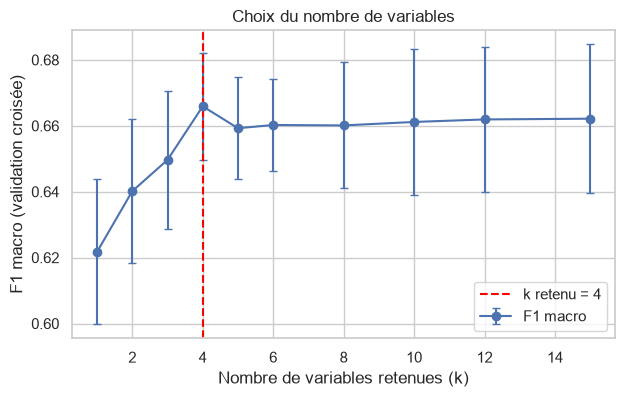

In [31]:
# --- (a) Stabilité des importances sur les 15 arbres ---
M = pd.DataFrame(importances_arbres)           # lignes : arbres ; colonnes : variables
stabilite = pd.DataFrame({
    "importance moy": M.mean(),
    "écart-type": M.std(),
    "fréquence (%)": (M > 0).mean() * 100,    # % d'arbres où la variable est utilisée
}).sort_values("importance moy", ascending=False)
stabilite["cumul"] = stabilite["importance moy"].cumsum() / stabilite["importance moy"].sum()
stabilite["famille"] = stabilite.index.map(famille_de)
print("Top 15 des variables (moyenne sur 15 arbres) :")
print(stabilite.head(15).round(3))

# --- (b) Importance par famille (somme des variables de chaque famille, par arbre) ---
par_famille = M.T.groupby(M.columns.map(famille_de)).sum().T
print("\nImportance par famille :")
print(pd.DataFrame({"moy": par_famille.mean(), "écart-type": par_famille.std()})
      .sort_values("moy", ascending=False).round(3))

# --- (c) Courbe F1 en fonction du nombre k de variables ---
courbe = pd.DataFrame([{"k": k, "F1 macro (moy)": np.mean(v), "écart-type": np.std(v),
                        "F1 Enrolled (moy)": np.mean(f1_enrolled[k])}
                       for k, v in f1_macro.items()])
print("\nF1 en fonction du nombre de variables (k) :")
print(courbe.round(4).to_string(index=False))
print("(Au-delà du nombre de variables réellement utilisées par l'arbre, "
      "les lignes se répètent : c'est normal.)")

# --- (d) Choix de k : plus petit k à moins d'un écart-type du meilleur F1 macro ---
c_num = courbe[courbe["k"] != "toutes"].copy()
c_num["k"] = c_num["k"].astype(int)
m = c_num.sort_values("F1 macro (moy)", ascending=False).iloc[0]
seuil_k = m["F1 macro (moy)"] - m["écart-type"]
k_retenu = int(c_num[c_num["F1 macro (moy)"] >= seuil_k]["k"].min())
selected_features = list(stabilite.index[:k_retenu])
print(f"\nk retenu = {k_retenu} (seuil F1 macro = {seuil_k:.4f})")
print("Importance cumulée des variables retenues :", round(stabilite["cumul"].iloc[k_retenu - 1], 3))
print("Variables retenues :", selected_features)

# Graphique : courbe F1 en fonction de k
plt.figure(figsize=(7, 4))
plt.errorbar(c_num["k"], c_num["F1 macro (moy)"], yerr=c_num["écart-type"],
             marker="o", capsize=3, label="F1 macro")
plt.axvline(k_retenu, color="red", linestyle="--", label=f"k retenu = {k_retenu}")
plt.xlabel("Nombre de variables retenues (k)")
plt.ylabel("F1 macro (validation croisée)")
plt.title("Choix du nombre de variables")
plt.legend()
plt.savefig("figures/04_courbe_f1_selon_k.png", dpi=200, bbox_inches="tight")
plt.show()

In [32]:
# Types des variables retenues (pour que P2 et P3 sachent comment les encoder)
sel_info = {
    "selected_features": selected_features,
    "binaires": [c for c in selected_features if c in binary_cols],
    "nominales": [c for c in selected_features if c in nominal_cols],
    "numeriques": [c for c in selected_features if c in numeric_cols],
    "methode": "Arbre de décision personnalisé (entropie), importance moyenne sur "
               "15 arbres (CV 5 plis x 3), k choisi par F1 macro (règle 1 écart-type)",
    "hyperparametres_arbre": BEST_PARAMS,
    "k_retenu": k_retenu,
}
with open("data_split/selected_features.json", "w", encoding="utf-8") as f:
    json.dump(sel_info, f, ensure_ascii=False, indent=2)

# Taille du jeu de données prétraité qu'auront P2 et P3
prep_sel = fit_preprocessor(X_train, selected_features, min_count=20)
print("Colonnes après prétraitement :", transform_preprocessor(X_train, prep_sel).shape[1])
print("Binaires :", sel_info["binaires"])
print("Nominales :", sel_info["nominales"])
print("Numériques :", sel_info["numeriques"])

Colonnes après prétraitement : 20
Binaires : ['Tuition fees up to date']
Nominales : ['Course']
Numériques : ['Curricular units 2nd sem (approved)', 'Curricular units 1st sem (evaluations)']


                                           Modèle  Précision  F1 macro  F1 Dropout  F1 Enrolled  F1 Graduate  Feuilles
  Base (36 var., prof. 5, feuille 10, sans poids)     0.7345    0.6241      0.7276       0.3020       0.8427        30
Amélioré (36 var., prof. 5, feuille 60, balanced)     0.6723    0.6466      0.7426       0.4390       0.7580        24
        Grand arbre élagué (36 var., alpha=0.002)     0.6994    0.6651      0.7528       0.4541       0.7883        18
                    Amélioré + sélection (4 var.)     0.6983    0.6647      0.7183       0.4744       0.8014        20


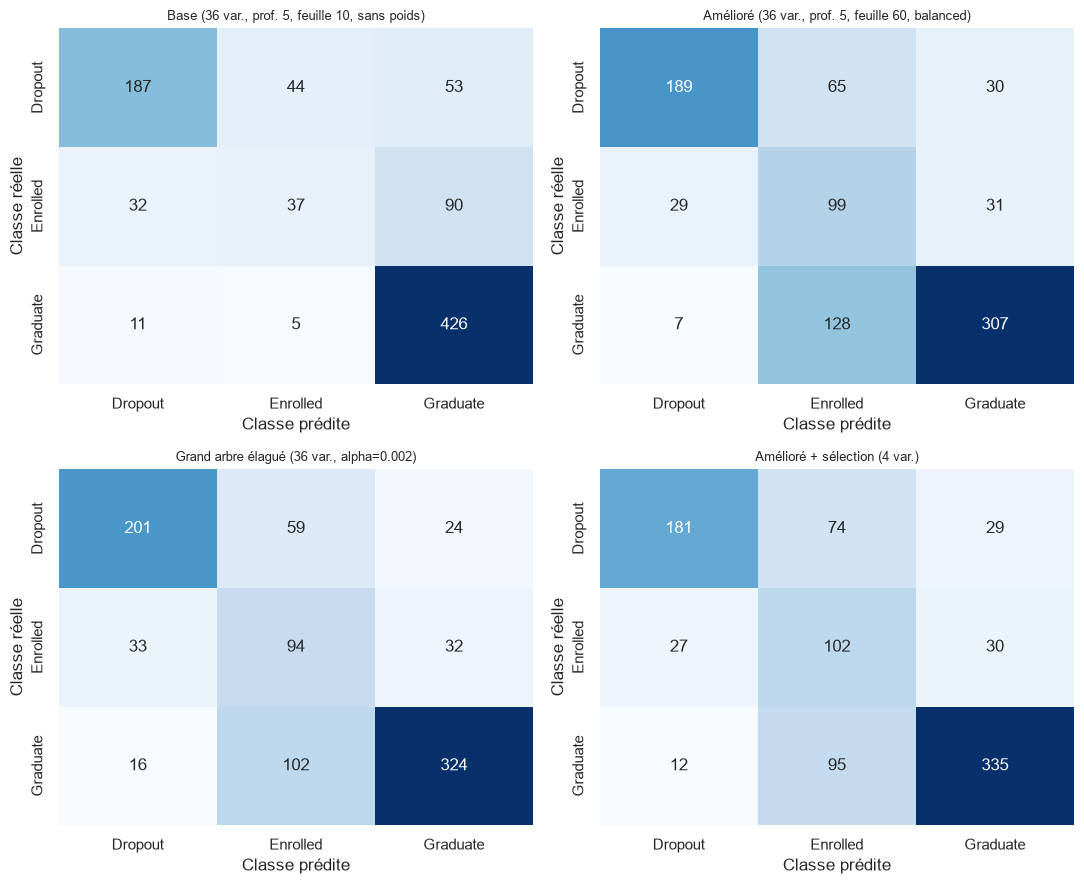

In [33]:
from sklearn.metrics import confusion_matrix

# --- On entraîne chaque variante sur TOUT le train, puis on évalue sur le TEST ---
# Les réglages ont été choisis avant, par validation croisée : on ne les modifie plus.
arbres = {}

# 1) Version de base (arbre standard, réglages par défaut raisonnables)
arbres["Base (36 var., prof. 5, feuille 10, sans poids)"] = (
    ArbreDecision(nominal_features=nominal_cols, max_depth=5, min_samples_leaf=10)
    .fit(X_train[all_features], y_train), all_features)

# 2) Amélioré : pré-élagage + pondération des classes (BEST_PARAMS)
arbres["Amélioré (36 var., prof. 5, feuille 60, balanced)"] = (
    ArbreDecision(nominal_features=nominal_cols, **BEST_PARAMS)
    .fit(X_train[all_features], y_train), all_features)

# 3) Grand arbre élagué (coût-complexité, alpha choisi par validation croisée)
grand = ArbreDecision(nominal_features=nominal_cols, **params_grand).fit(X_train[all_features], y_train)
arbres["Grand arbre élagué (36 var., alpha=0.002)"] = (elaguer_arbre(grand, 0.002), all_features)

# 4) Amélioré + sélection de variables (k retenu)
arbres[f"Amélioré + sélection ({k_retenu} var.)"] = (
    ArbreDecision(nominal_features=nominal_cols, **BEST_PARAMS)
    .fit(X_train[selected_features], y_train), selected_features)

# --- Évaluation sur le test ---
lignes, matrices = [], {}
for nom, (arbre, feats) in arbres.items():
    pred = arbre.predict(X_test[feats])
    f1_classes = f1_score(y_test, pred, average=None, labels=CLASSES)
    lignes.append({
        "Modèle": nom,
        "Précision": round((pred == y_test.to_numpy()).mean(), 4),
        "F1 macro": round(f1_score(y_test, pred, average="macro"), 4),
        "F1 Dropout": round(f1_classes[0], 4),
        "F1 Enrolled": round(f1_classes[1], 4),
        "F1 Graduate": round(f1_classes[2], 4),
        "Feuilles": arbre.nb_feuilles(),
    })
    matrices[nom] = confusion_matrix(y_test, pred, labels=CLASSES)

resultats_test = pd.DataFrame(lignes)
print(resultats_test.to_string(index=False))
resultats_test.to_csv("resultats_arbre_test.csv", index=False)

# --- Matrices de confusion (lignes = classe réelle, colonnes = classe prédite) ---
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (nom, mat) in zip(axes.ravel(), matrices.items()):
    sns.heatmap(mat, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=CLASSES, yticklabels=CLASSES)
    ax.set_title(nom, fontsize=9)
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Classe réelle")
plt.tight_layout()
plt.savefig("figures/05_matrices_confusion.png", dpi=200, bbox_inches="tight")
plt.show()

In [34]:
# On rééchantillonne 1000 fois le jeu de test (avec remise) pour mesurer l'incertitude
# du F1 macro. Les MÊMES rééchantillons servent pour tous les modèles : la comparaison
# à la version de base est donc "appariée" (plus fiable qu'une comparaison séparée).
rng = np.random.default_rng(SEED)
y_true = y_test.to_numpy()
n_test = len(y_true)
preds = {nom: arbre.predict(X_test[feats]) for nom, (arbre, feats) in arbres.items()}

B = 1000
f1_boot = {nom: np.empty(B) for nom in preds}
for b in range(B):
    idx = rng.integers(0, n_test, n_test)            # étudiants tirés avec remise
    for nom, p in preds.items():
        f1_boot[nom][b] = f1_score(y_true[idx], p[idx], average="macro")

ref = list(preds)[0]                                  # la version de base
lignes = []
for nom in preds:
    lo, hi = np.percentile(f1_boot[nom], [2.5, 97.5])
    d = f1_boot[nom] - f1_boot[ref]                   # écart avec la base, rééchantillon par rééchantillon
    dlo, dhi = np.percentile(d, [2.5, 97.5])
    lignes.append({"Modèle": nom,
                   "F1 macro (test)": round(f1_score(y_true, preds[nom], average="macro"), 4),
                   "IC 95 %": f"[{lo:.3f} ; {hi:.3f}]",
                   "Écart vs base": round(d.mean(), 4),
                   "IC 95 % de l'écart": f"[{dlo:+.3f} ; {dhi:+.3f}]",
                   "P(mieux que base)": round((d > 0).mean(), 3)})
print(pd.DataFrame(lignes).to_string(index=False))

                                           Modèle  F1 macro (test)         IC 95 %  Écart vs base IC 95 % de l'écart  P(mieux que base)
  Base (36 var., prof. 5, feuille 10, sans poids)           0.6241 [0.591 ; 0.659]         0.0000  [+0.000 ; +0.000]              0.000
Amélioré (36 var., prof. 5, feuille 60, balanced)           0.6466 [0.615 ; 0.675]         0.0208  [-0.016 ; +0.059]              0.847
        Grand arbre élagué (36 var., alpha=0.002)           0.6651 [0.634 ; 0.697]         0.0400  [+0.005 ; +0.077]              0.987
                    Amélioré + sélection (4 var.)           0.6647 [0.632 ; 0.695]         0.0397  [+0.005 ; +0.073]              0.989


In [35]:
# Le guide demande de préciser À QUEL MOMENT le modèle prédit.
# On compare trois scénarios avec les mêmes réglages (BEST_PARAMS), en validation
# croisée sur le TRAIN uniquement.
sem2 = [c for c in semester_cols if "2nd sem" in c]
scenarios = {
    "A : fin du 2e semestre (36 variables)": all_features,
    "B : fin du 1er semestre (sans le 2e sem., 30 var.)": [c for c in all_features if c not in sem2],
    "C : dès l'inscription (sans variables de semestre, 24 var.)":
        [c for c in all_features if c not in semester_cols],
}
lignes = []
for nom, feats in scenarios.items():
    moy, ecart, f1_enr = evaluer_cv(BEST_PARAMS, X_train[feats], y_train)
    arbre = ArbreDecision(nominal_features=nominal_cols, **BEST_PARAMS).fit(X_train[feats], y_train)
    top4 = ", ".join(arbre.feature_importances_.head(4).index)
    lignes.append({"Scénario": nom, "F1 macro (CV)": round(moy, 4), "écart-type": round(ecart, 4),
                   "F1 Enrolled": round(f1_enr, 4), "4 variables principales": top4})
pd.set_option("display.max_colwidth", 120)
print(pd.DataFrame(lignes).to_string(index=False))

                                                   Scénario  F1 macro (CV)  écart-type  F1 Enrolled                                                                                                                4 variables principales
                      A : fin du 2e semestre (36 variables)         0.6736      0.0238       0.4889                           Curricular units 2nd sem (approved), Tuition fees up to date, Course, Curricular units 1st sem (evaluations)
         B : fin du 1er semestre (sans le 2e sem., 30 var.)         0.6283      0.0139       0.4314 Curricular units 1st sem (approved), Tuition fees up to date, Curricular units 1st sem (grade), Curricular units 1st sem (evaluations)
C : dès l'inscription (sans variables de semestre, 24 var.)         0.5021      0.0118       0.3420                                                                 Tuition fees up to date, Scholarship holder, Course, Age at enrollment
